###Step 1: ANN — Artificial Neural Network
1.1  Data Loading & Preprocessing

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from tensorflow import keras
from tensorflow.keras.utils import to_categorical

data = load_wine(as_frame=True)
df = data.frame

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
print(df.head())
print("\nMissing Values:")
print(df.isnull().sum())
print("\nStatistical Description:")
print(df.describe())

Dataset Shape: (178, 14)

First 5 Rows:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_dilu

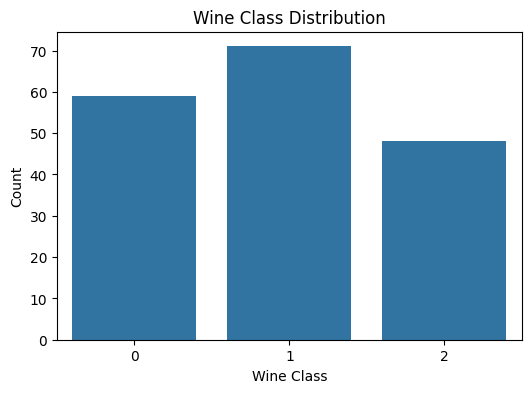

In [2]:
plt.figure(figsize=(6, 4))
sns.countplot(x='target', data=df)
plt.title("Wine Class Distribution")
plt.xlabel("Wine Class")
plt.ylabel("Count")
plt.show()

In [3]:
print(df.describe().loc[['min', 'max']])

     alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
min    11.03        0.74  1.36               10.6       70.0           0.98   
max    14.83        5.80  3.23               30.0      162.0           3.88   

     flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
min        0.34                  0.13             0.41             1.28  0.48   
max        5.08                  0.66             3.58            13.00  1.71   

     od280/od315_of_diluted_wines  proline  target  
min                          1.27    278.0     0.0  
max                          4.00   1680.0     2.0  


In [4]:
X = df.drop('target', axis=1)
y = df['target']
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42,stratify=y)
print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)

Features Shape: (178, 13)
Target Shape: (178,)
X_train Shape: (142, 13)
X_test Shape: (36, 13)


In [5]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [6]:
y_train = to_categorical(y_train, num_classes=3)
y_test = to_categorical(y_test, num_classes=3)
print("Y_train Shape:", y_train.shape)
print("Y_test Shape:", y_test.shape)

Y_train Shape: (142, 3)
Y_test Shape: (36, 3)


1.2 Build the ANN

In [7]:
model = keras.Sequential([
    keras.layers.Input(shape=(13,)),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(8, activation='relu'),
    keras.layers.Dense(3, activation='softmax')])

model.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 387 (1.51 KB)

 Trainable params: 387 (1.51 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
inputs = 13
neurons = 16
parameters = (inputs * neurons) + neurons
print("First Hidden Layer Parameters:", parameters)

First Hidden Layer Parameters: 224


1.3 Train & Evaluate

Epoch 1/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.3628 - loss: 1.0768 - val_accuracy: 0.6207 - val_loss: 0.8377
Epoch 2/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3805 - loss: 0.9479 - val_accuracy: 0.6897 - val_loss: 0.7459
Epoch 3/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4779 - loss: 0.8522 - val_accuracy: 0.7241 - val_loss: 0.6704
Epoch 4/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5664 - loss: 0.7732 - val_accuracy: 0.7241 - val_loss: 0.6090
Epoch 5/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6283 - loss: 0.7078 - val_accuracy: 0.7241 - val_loss: 0.5609
Epoch 6/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6549 - loss: 0.6542 - val_accuracy: 0.7586 - val_loss: 0.5229
Epoch 7/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6991 - loss: 0.6106 - val_accuracy: 0.8276 - val_loss: 0.4858
Epoch 8/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7434 - loss: 0.5640 - val_accuracy: 0.8276 - val_los

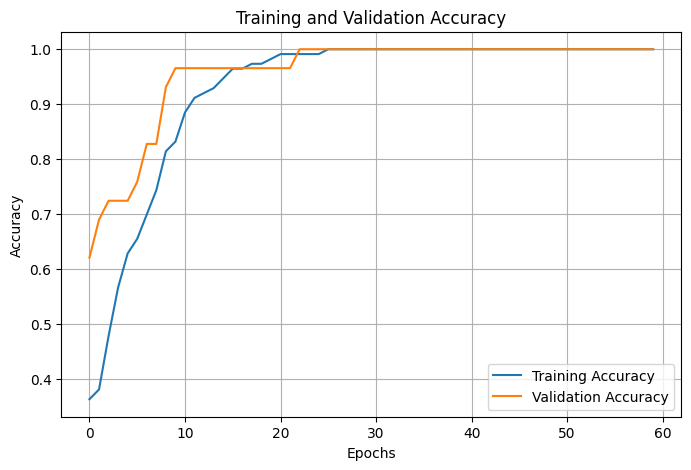

In [9]:
history = model.fit(X_train,y_train,epochs=60,batch_size=8,validation_split=0.2,verbose=1)
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

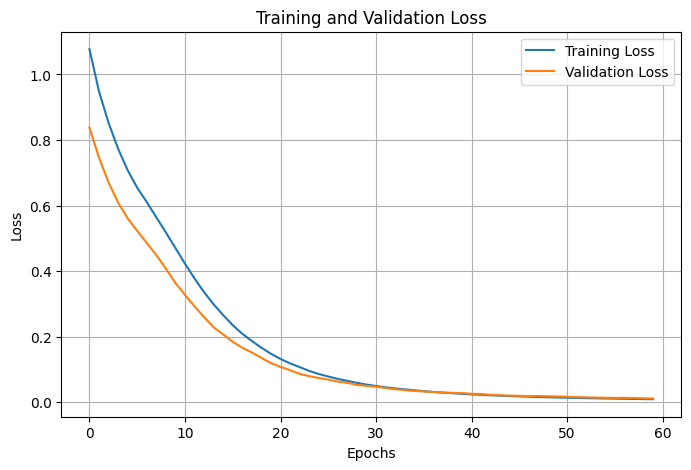

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

In [11]:
y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test, axis=1)

print("Predicted Classes:")
print(y_pred)
print("\nActual Classes:")
print(y_true)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
Predicted Classes:
[0 2 0 0 1 0 0 1 1 2 1 2 0 1 0 1 1 0 1 0 1 1 0 0 1 1 0 2 1 2 0 2 1 2 2 2]

Actual Classes:
[0 2 0 1 1 0 0 1 1 2 1 2 0 2 0 1 1 0 1 0 1 1 0 0 1 1 0 2 1 2 0 2 1 2 2 2]


In [12]:
accuracy = accuracy_score(y_true, y_pred)
print("Test Accuracy:", accuracy * 100, "%")

print("Classification Report:")
print(classification_report(y_true, y_pred))

Test Accuracy: 94.44444444444444 %
Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96        12
           1       0.93      0.93      0.93        14
           2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.95      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36



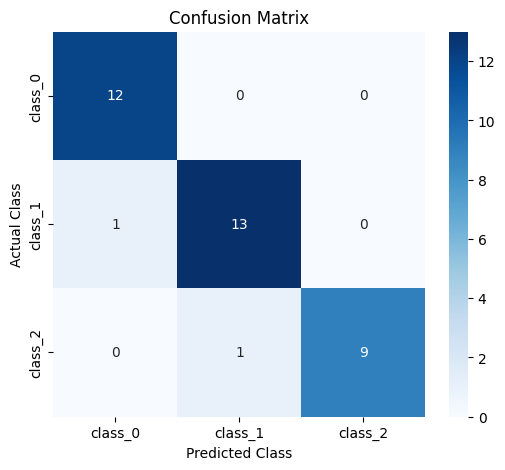

In [13]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))

sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=data.target_names,yticklabels=data.target_names)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

1.4 Save & Reflect

In [14]:
model.save('ann_wine_model.h5')
print("Model saved successfully!")

Model saved successfully!


Markdown answers for your practical
1. What does each layer do?
- Input Layer: Accepts 13 chemical features of wine.
- First Hidden Layer: Contains 16 neurons with ReLU activation to learn patterns.
- Second Hidden Layer: Contains 8 neurons to learn more complex relationships.
- Output Layer: Contains 3 neurons with Softmax activation to predict the wine class.
2. Why do we use Softmax instead of Sigmoid?

Softmax is used because this is a multi-class classification problem. It calculates the probability of each of the three classes, and the probabilities add up to 1.

3. Why is categorical_crossentropy the right loss function?

Categorical Crossentropy is suitable for multi-class classification when target labels are one-hot encoded. It measures the difference between actual class probabilities and predicted probabilities.

4. What do the 3 output numbers add up to?

The three output probabilities add up to 1 (or approximately 1 due to floating-point precision).

##Step 2: OpenCV — Colour, Morphology & Face Detection
2.1  Load & Display

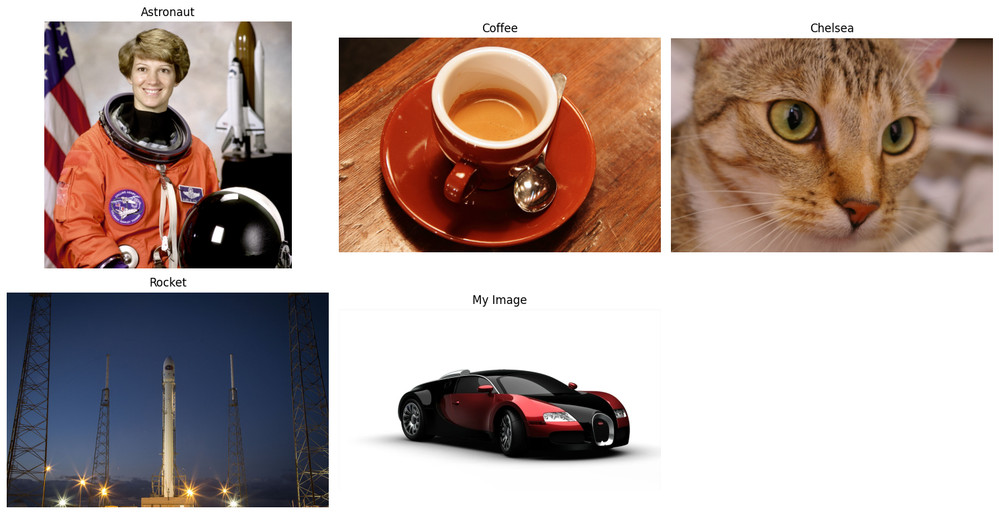


 Astronaut
Shape: (512, 512, 3)
Data Type: uint8
Minimum Pixel Value: 0
Maximum Pixel Value: 255
Mean Brightness: 114.59900410970052

 Coffee
Shape: (400, 600, 3)
Data Type: uint8
Minimum Pixel Value: 0
Maximum Pixel Value: 255
Mean Brightness: 98.61595416666667

 Chelsea
Shape: (300, 451, 3)
Data Type: uint8
Minimum Pixel Value: 0
Maximum Pixel Value: 231
Mean Brightness: 115.30514166050752

 Rocket
Shape: (427, 640, 3)
Data Type: uint8
Minimum Pixel Value: 0
Maximum Pixel Value: 255
Mean Brightness: 65.27705893832943

 My Image
Shape: (720, 1280, 3)
Data Type: uint8
Minimum Pixel Value: 0
Maximum Pixel Value: 255
Mean Brightness: 191.36807002314814


In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

img1 = cv2.cvtColor(data.astronaut(), cv2.COLOR_RGB2BGR)
img2 = cv2.cvtColor(data.coffee(), cv2.COLOR_RGB2BGR)
img3 = cv2.cvtColor(data.chelsea(), cv2.COLOR_RGB2BGR)
img4 = cv2.cvtColor(data.rocket(), cv2.COLOR_RGB2BGR)
img5 = cv2.imread('my_image.jpg')

if img5 is None:
    raise FileNotFoundError("Image not found. Check the image path.")

images = [img1, img2, img3, img4, img5]

names = ['Astronaut', 'Coffee', 'Chelsea', 'Rocket', 'My Image']

plt.figure(figsize=(15, 8))

for i, img in enumerate(images):
    plt.subplot(2, 3, i + 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(names[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

for name, img in zip(names, images):
    print("\n", name)
    print("Shape:", img.shape)
    print("Data Type:", img.dtype)
    print("Minimum Pixel Value:", img.min())
    print("Maximum Pixel Value:", img.max())
    print("Mean Brightness:", img.mean())

2.2 Preprocessing Operations

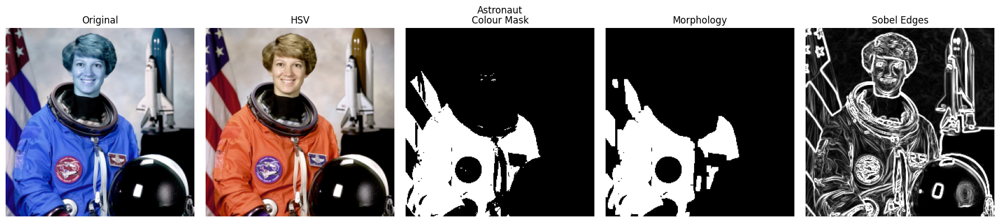

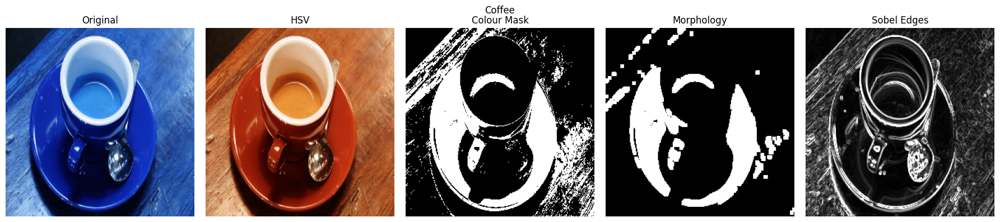

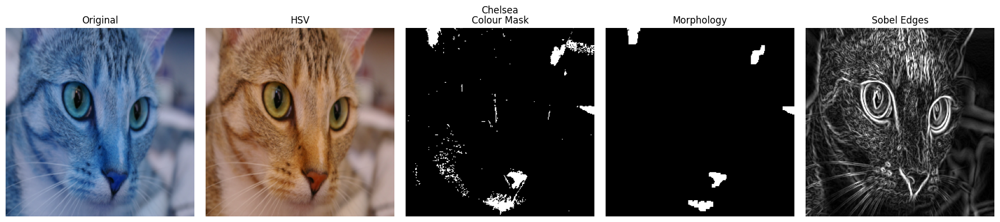

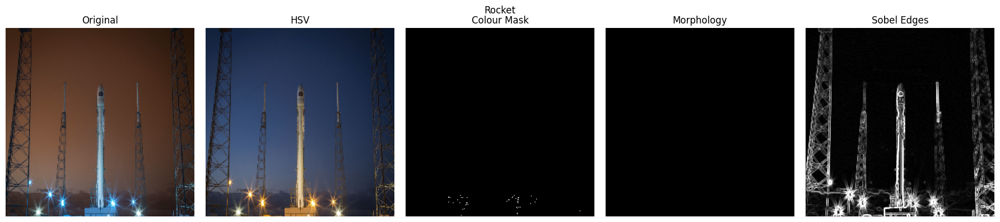

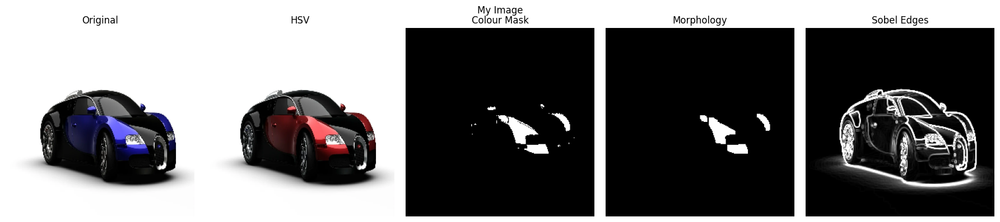

In [16]:
processed_images = []
kernel = np.ones((5, 5), np.uint8)

for img in images:

    resized = cv2.resize(img, (256, 256))
    hsv = cv2.cvtColor(resized, cv2.COLOR_BGR2HSV)

    lower1 = np.array([0, 100, 100])
    upper1 = np.array([10, 255, 255])

    lower2 = np.array([160, 100, 100])
    upper2 = np.array([180, 255, 255])

    mask1 = cv2.inRange(hsv, lower1, upper1)
    mask2 = cv2.inRange(hsv, lower2, upper2)

    mask = cv2.bitwise_or(mask1, mask2)

    erosion = cv2.erode(mask, kernel, iterations=1)
    morphology = cv2.dilate(erosion, kernel, iterations=1)

    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    sobel = cv2.magnitude(sobel_x, sobel_y)
    sobel = cv2.convertScaleAbs(sobel)
    processed_images.append((resized, hsv, mask, morphology, sobel))

    fig, axes = plt.subplots(1, 5, figsize=(18, 4))
    outputs = [resized,cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB),mask,morphology,sobel]
    titles = ['Original', 'HSV', 'Colour Mask', 'Morphology', 'Sobel Edges']

    for ax, output, title in zip(axes, outputs, titles):
        if len(output.shape) == 2:
            ax.imshow(output, cmap='gray')
        else:
            ax.imshow(output)

        ax.set_title(title)
        ax.axis('off')

    plt.suptitle(names[len(processed_images) - 1])
    plt.tight_layout()
    plt.show()

2.3 Face Detection with Haar Cascade

In [17]:
# !pip uninstall opencv-python opencv-contrib-python opencv-python-headless opencv-contrib-python-headless -y

In [18]:
# !pip install opencv-contrib-python

In [19]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print(cv2.__version__)
print(hasattr(cv2, 'CascadeClassifier'))

4.14.0
True


In [20]:
import urllib.request

url = "https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalface_default.xml"
urllib.request.urlretrieve(url, "haarcascade_frontalface_default.xml")
print("XML file downloaded successfully!")

XML file downloaded successfully!


In [21]:
face_cascade = cv2.CascadeClassifier('haarcascade_frontalface_default.xml')
print("Cascade Loaded:", not face_cascade.empty())

Cascade Loaded: True


In [22]:
face_cascade = cv2.CascadeClassifier('haarcascade_frontalface_default.xml')

XML File Exists: True
Cascade Loaded: True
Astronaut Number of Faces: 1


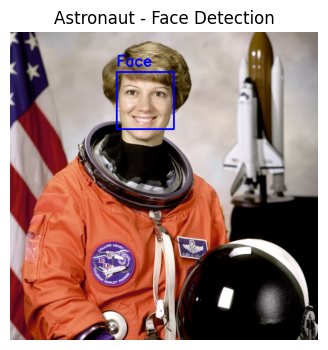

Coffee Number of Faces: 0


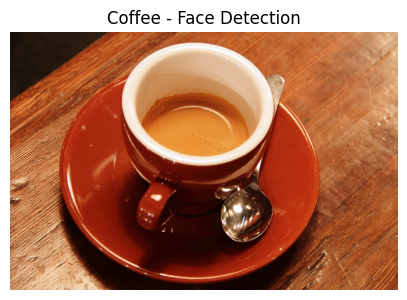

Chelsea Number of Faces: 0


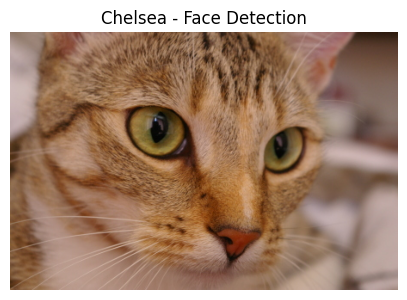

Rocket Number of Faces: 0


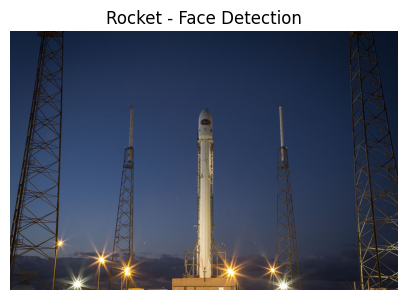

My Image Number of Faces: 0


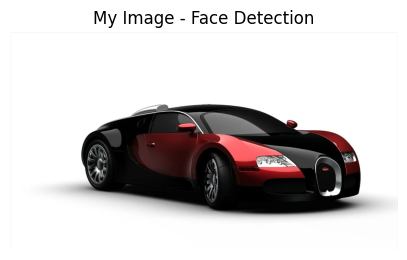

In [23]:
import os
import cv2
import matplotlib.pyplot as plt

xml_path = os.path.abspath('haarcascade_frontalface_default.xml')

face_cascade = cv2.CascadeClassifier(xml_path)

print("XML File Exists:", os.path.exists(xml_path))
print("Cascade Loaded:", not face_cascade.empty())

if face_cascade.empty():
    raise ValueError("Cascade XML file is not loaded properly")

face_images = []

for name, img in zip(names, images):

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray,scaleFactor=1.1,minNeighbors=5)

    output = img.copy()

    for (x, y, w, h) in faces:
        cv2.rectangle(output, (x, y), (x+w, y+h), (255, 0, 0), 2)
        cv2.putText(output,'Face',(x, y-10),cv2.FONT_HERSHEY_SIMPLEX,0.8,(255, 0, 0),2)

    face_images.append(output)

    print(name, "Number of Faces:", len(faces))

    plt.figure(figsize=(5,4))
    plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    plt.title(name + " - Face Detection")
    plt.axis('off')
    plt.show()

minNeighbors: 2
Number of Faces: 1


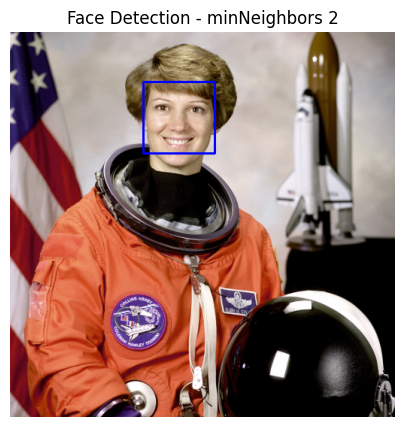

minNeighbors: 8
Number of Faces: 1


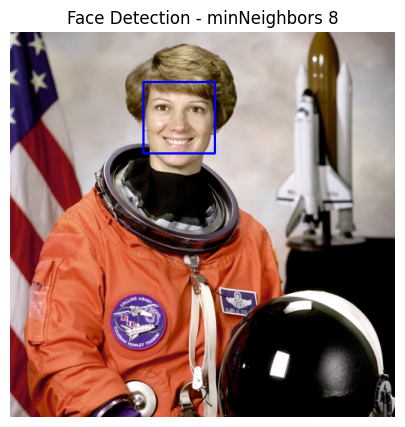

In [24]:
img = images[0]
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

for neighbors in [2, 8]:
    faces = face_cascade.detectMultiScale(gray,scaleFactor=1.1,minNeighbors=neighbors)
    output = img.copy()

    for (x, y, w, h) in faces:
        cv2.rectangle(output, (x, y), (x+w, y+h), (255, 0, 0), 2)

    print("minNeighbors:", neighbors)
    print("Number of Faces:", len(faces))
    plt.figure(figsize=(6, 5))
    plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    plt.title("Face Detection - minNeighbors " + str(neighbors))
    plt.axis('off')
    plt.show()

2.4 Summary

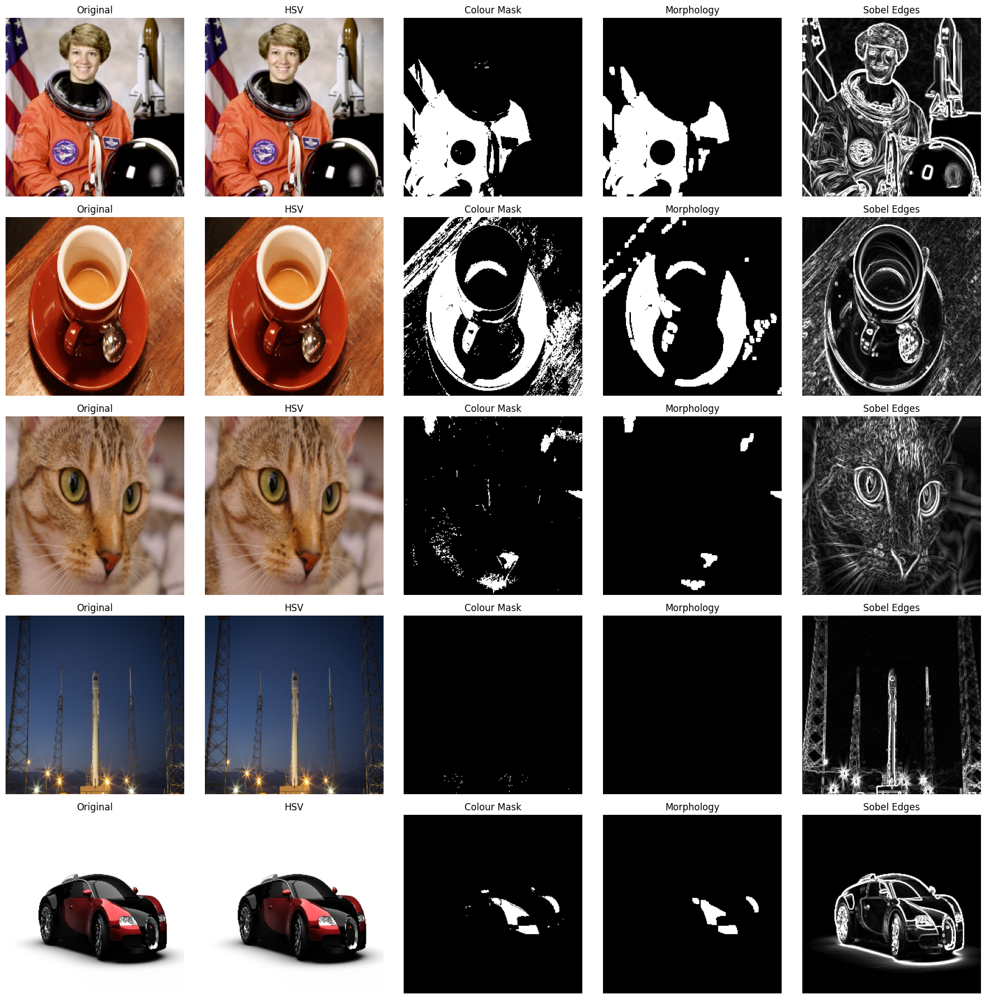

In [25]:
fig, axes = plt.subplots(5, 5, figsize=(18, 18))

titles = ['Original', 'HSV', 'Colour Mask', 'Morphology', 'Sobel Edges']

for i, (name, results) in enumerate(zip(names, processed_images)):
    for j, output in enumerate(results):

        if j == 1:
            output = cv2.cvtColor(output, cv2.COLOR_HSV2RGB)
        if len(output.shape) == 2:
            axes[i, j].imshow(output, cmap='gray')
        else:
            axes[i, j].imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB) if j == 0 else output)

        axes[i, j].set_title(titles[j])
        axes[i, j].axis('off')

plt.tight_layout()
plt.show()

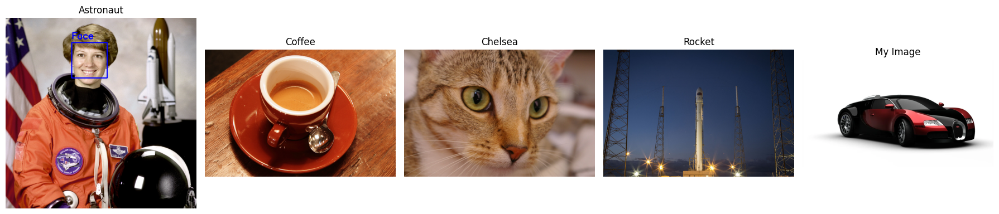

In [26]:
fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for ax, img, name in zip(axes, face_images, names):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(name)
    ax.axis('off')

plt.tight_layout()
plt.show()

1. Why is HSV easier than BGR for colour selection?

HSV separates colour information (Hue) from brightness (Value) and saturation. Therefore, selecting a particular colour is easier using HSV than BGR.

2. What do erosion and dilation do to a mask?
- Erosion: Removes small white noise and shrinks white regions.
- Dilation: Expands white regions and helps fill small gaps.
3. How is a Haar Cascade different from a CNN?
- Haar Cascade: Uses predefined hand-crafted features to detect faces.
- CNN: Automatically learns features from training images using neural networks.

###Step 3: CNN — Convolutional Neural Network
3.1  Data Loading & Preparation

In [27]:
from tensorflow import keras
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train = X_train[:20000]
y_train = y_train[:20000]
X_test = X_test[:4000]
y_test = y_test[:4000]

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (20000, 28, 28)
Testing Data Shape: (4000, 28, 28)


In [28]:
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)

y_train = to_categorical(y_train, num_classes=10)
y_test = to_categorical(y_test, num_classes=10)

print("Y_train Shape:", y_train.shape)
print("Y_test Shape:", y_test.shape)

X_train Shape: (20000, 28, 28, 1)
X_test Shape: (4000, 28, 28, 1)
Y_train Shape: (20000, 10)
Y_test Shape: (4000, 10)


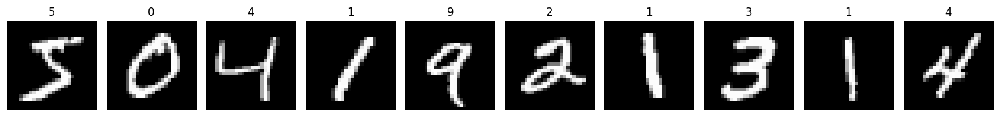

In [29]:
plt.figure(figsize=(15, 4))

for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap='gray')
    plt.title(str(np.argmax(y_train[i])))
    plt.axis('off')

plt.tight_layout()
plt.show()

3.2 Build the CNN and the ANN Baseline

In [30]:
cnn_model = keras.Sequential([
    keras.layers.Conv2D(16, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(32, (3, 3), activation='relu'),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Flatten(),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(10, activation='softmax')])

cnn_model.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])
cnn_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,714 (221.54 KB)

 Trainable params: 56,714 (221.54 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
ann_model = keras.Sequential([

    keras.layers.Flatten(input_shape=(28, 28, 1)),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(10, activation='softmax')])

ann_model.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])
ann_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
print("CNN Total Parameters:", cnn_model.count_params())
print("ANN Total Parameters:", ann_model.count_params())

CNN Total Parameters: 56714
ANN Total Parameters: 109386


3.3 Train & Evaluate

In [33]:
if len(y_train.shape) == 3:
    y_train = np.argmax(y_train, axis=-1)
if len(y_test.shape) == 3:
    y_test = np.argmax(y_test, axis=-1)

if len(y_train.shape) == 1 or y_train.shape[-1] != 10:
    y_train = to_categorical(y_train, num_classes=10)
if len(y_test.shape) == 1 or y_test.shape[-1] != 10:
    y_test = to_categorical(y_test, num_classes=10)

cnn_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
history_cnn = cnn_model.fit(X_train, y_train, epochs=8, batch_size=64, validation_split=0.1, callbacks=[early_stop], verbose=1)

Epoch 1/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.8694 - loss: 0.4353 - val_accuracy: 0.9565 - val_loss: 0.1410
Epoch 2/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 11s 35ms/step - accuracy: 0.9644 - loss: 0.1170 - val_accuracy: 0.9730 - val_loss: 0.0961
Epoch 3/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 10s 34ms/step - accuracy: 0.9751 - loss: 0.0799 - val_accuracy: 0.9775 - val_loss: 0.0735
Epoch 4/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.9814 - loss: 0.0627 - val_accuracy: 0.9860 - val_loss: 0.0545
Epoch 5/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 10s 35ms/step - accuracy: 0.9858 - loss: 0.0495 - val_accuracy: 0.9865 - val_loss: 0.0475
Epoch 6/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 9s 34ms/step - accuracy: 0.9867 - loss: 0.0408 - val_accuracy: 0.9830 - val_loss: 0.0593
Epoch 7/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.9883 - loss: 0.0360 - val_accuracy: 0.9700 - val_loss: 0.0875


In [34]:
history_ann = ann_model.fit(X_train,y_train,epochs=8,batch_size=64,validation_split=0.1,verbose=1)

Epoch 1/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8634 - loss: 0.4798 - val_accuracy: 0.9425 - val_loss: 0.2075
Epoch 2/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9442 - loss: 0.1868 - val_accuracy: 0.9545 - val_loss: 0.1564
Epoch 3/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9626 - loss: 0.1277 - val_accuracy: 0.9520 - val_loss: 0.1581
Epoch 4/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9712 - loss: 0.0974 - val_accuracy: 0.9650 - val_loss: 0.1232
Epoch 5/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9798 - loss: 0.0679 - val_accuracy: 0.9665 - val_loss: 0.1284
Epoch 6/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9845 - loss: 0.0534 - val_accuracy: 0.9695 - val_loss: 0.1155
Epoch 7/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9883 - loss: 0.0410 - val_accuracy: 0.9720 - val_loss: 0.1109
Epoch 8/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9926 - loss: 0.0303 - val_accuracy: 0.9675 - v

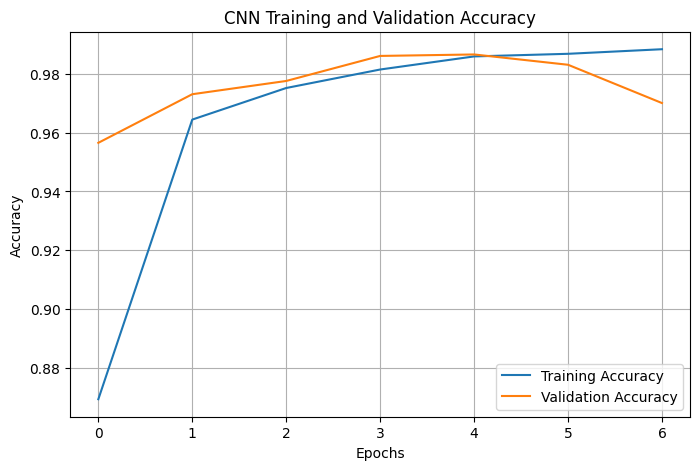

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(history_cnn.history['accuracy'], label='Training Accuracy')
plt.plot(history_cnn.history['val_accuracy'], label='Validation Accuracy')
plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

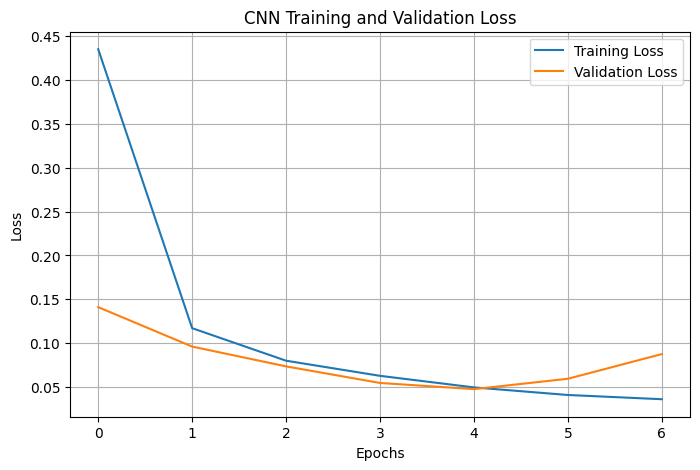

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(history_cnn.history['loss'], label='Training Loss')
plt.plot(history_cnn.history['val_loss'], label='Validation Loss')
plt.title("CNN Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

In [37]:
cnn_loss, cnn_accuracy = cnn_model.evaluate(X_test, y_test)
ann_loss, ann_accuracy = ann_model.evaluate(X_test, y_test)
print("CNN Test Accuracy:", cnn_accuracy * 100, "%")
print("ANN Test Accuracy:", ann_accuracy * 100, "%")

125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9762 - loss: 0.0713
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9565 - loss: 0.1421
CNN Test Accuracy: 97.62499928474426 %
ANN Test Accuracy: 95.6499993801117 %


In [38]:
results = pd.DataFrame({
    'Model': ['CNN', 'ANN'],
    'Total Parameters': [cnn_model.count_params(),ann_model.count_params()],
    'Test Accuracy': [cnn_accuracy * 100,ann_accuracy * 100]})

print(results)

  Model  Total Parameters  Test Accuracy
0   CNN             56714      97.624999
1   ANN            109386      95.649999


In [39]:
y_pred_prob = cnn_model.predict(X_test)

y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test, axis=1)

print(classification_report(y_true, y_pred))

125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       370
           1       0.99      0.98      0.99       450
           2       0.95      0.99      0.97       418
           3       0.97      0.99      0.98       408
           4       0.99      0.99      0.99       418
           5       0.98      0.97      0.98       372
           6       0.99      0.97      0.98       378
           7       0.96      0.98      0.97       411
           8       0.99      0.94      0.97       384
           9       0.98      0.96      0.97       391

    accuracy                           0.98      4000
   macro avg       0.98      0.98      0.98      4000
weighted avg       0.98      0.98      0.98      4000



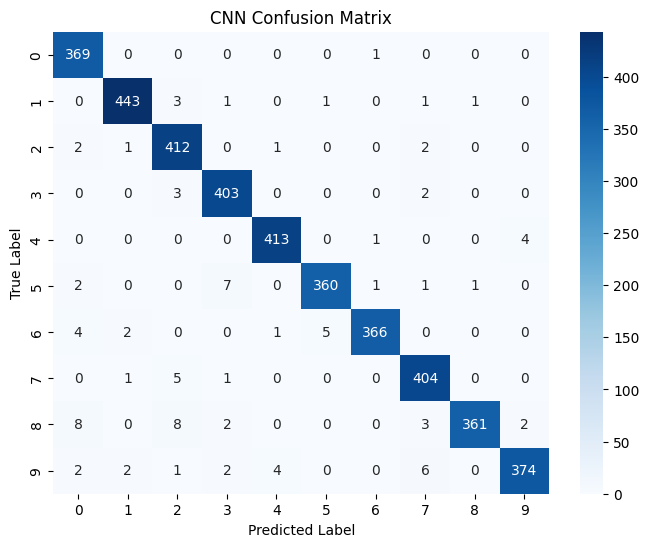

In [40]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

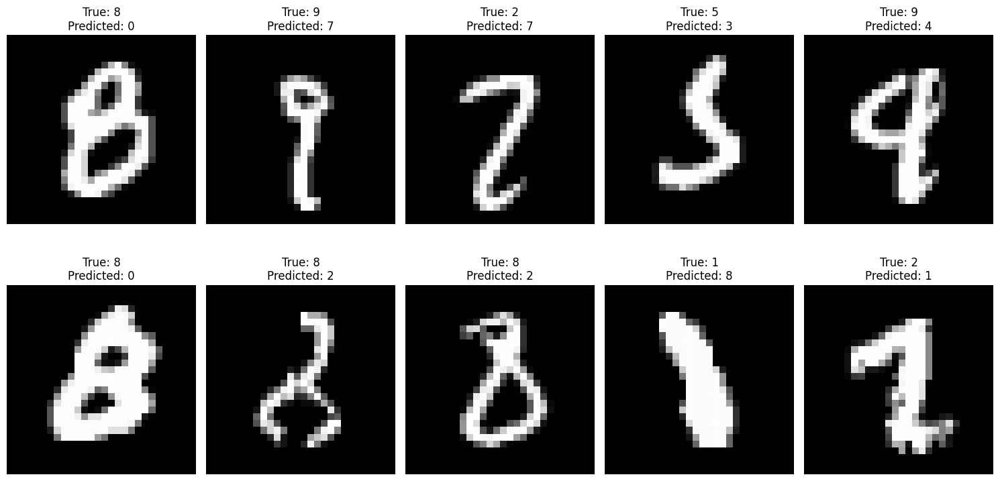

In [41]:
wrong_indices = np.where(y_pred != y_true)[0]

plt.figure(figsize=(15, 8))

for i, idx in enumerate(wrong_indices[:10]):

    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[idx].reshape(28, 28), cmap='gray')
    plt.title(
        "True: " + str(y_true[idx]) +
        "\nPredicted: " + str(y_pred[idx]))
    plt.axis('off')

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


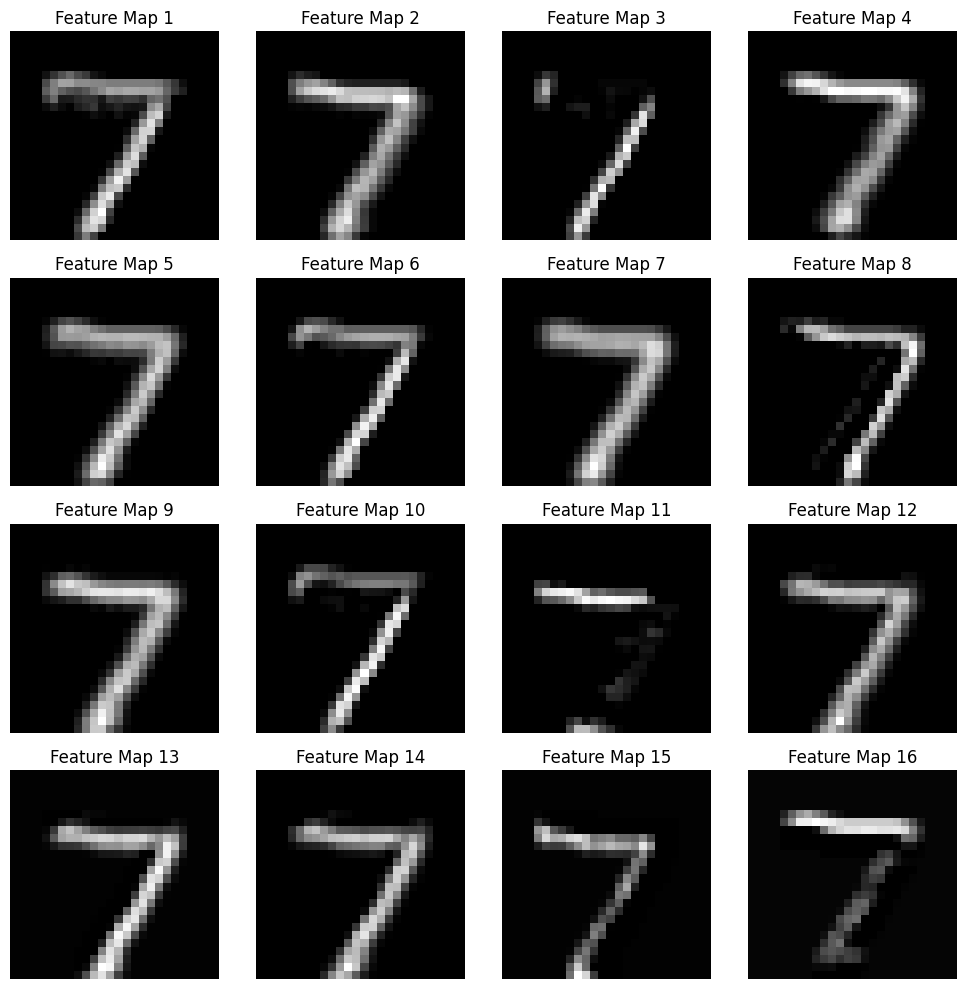

In [42]:
feature_model = keras.Model(
    inputs=cnn_model.inputs,
    outputs=cnn_model.layers[0].output
)

feature_maps = feature_model.predict(X_test[0:1])
plt.figure(figsize=(10, 10))

for i in range(16):

    plt.subplot(4, 4, i + 1)
    plt.imshow(feature_maps[0, :, :, i], cmap='gray')
    plt.title("Feature Map " + str(i + 1))
    plt.axis('off')
plt.tight_layout()
plt.show()

3.4 Save & Reflect

In [43]:
cnn_model.save('cnn_mnist_model.h5')
print("CNN Model Saved Successfully!")

CNN Model Saved Successfully!


1. What do the feature maps show you?

Feature maps show the important patterns detected by convolution filters, such as edges, curves, shapes and other features of handwritten digits.

2. Which model has fewer parameters and why?

CNN generally has fewer parameters because convolution layers use shared weights and local connections. ANN uses fully connected layers, which require more parameters.

3. What does MaxPooling do?

MaxPooling reduces the spatial size of feature maps by selecting the maximum value from each region. It reduces computation and helps retain important features.

4. Which digits did the CNN confuse and why might that be?

The CNN may confuse visually similar digits, such as 3 and 5, 4 and 9, or 7 and 1. This can happen because of similar handwriting styles, shapes and strokes.

###Step 4: RNN — Recurrent Neural Network
4.1  Data Loading & Preparation

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow import keras
from tensorflow.keras import layers

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"

df = pd.read_csv(url, parse_dates=['Date'])
print(df.head())
print("\nData Types:")
print(df.dtypes)
print("\nStatistical Description:")
print(df.describe())

        Date  Temp
0 1981-01-01  20.7
1 1981-01-02  17.9
2 1981-01-03  18.8
3 1981-01-04  14.6
4 1981-01-05  15.8

Data Types:
Date    datetime64[ns]
Temp           float64
dtype: object

Statistical Description:
                      Date         Temp
count                 3650  3650.000000
mean   1985-12-31 07:12:00    11.177753
min    1981-01-01 00:00:00     0.000000
25%    1983-07-02 06:00:00     8.300000
50%    1985-12-31 12:00:00    11.000000
75%    1988-06-30 18:00:00    14.000000
max    1990-12-31 00:00:00    26.300000
std                    NaN     4.071837


In [45]:
df['Temp'] = pd.to_numeric(df['Temp'], errors='coerce')

missing_before = df['Temp'].isnull().sum()
df['Temp'] = df['Temp'].interpolate()
missing_after = df['Temp'].isnull().sum()

print("Missing Values Before:", missing_before)
print("Missing Values After:", missing_after)
print("Values Fixed:", missing_before - missing_after)

Missing Values Before: 0
Missing Values After: 0
Values Fixed: 0


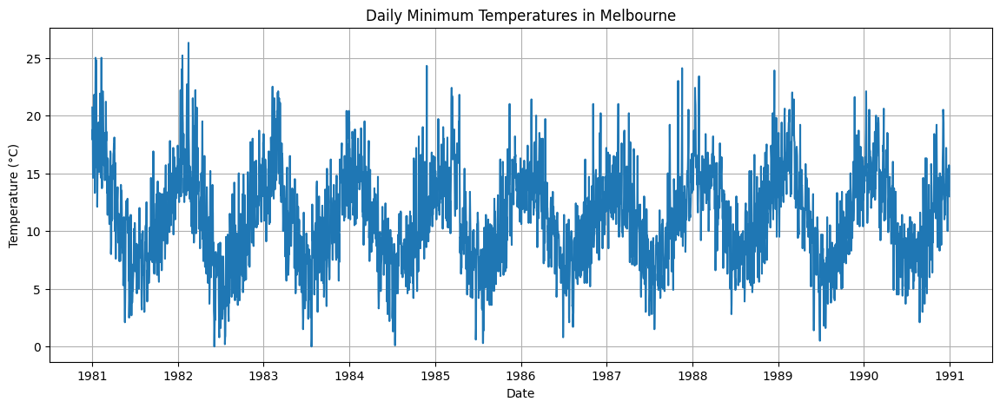

In [46]:
plt.figure(figsize=(14, 5))

plt.plot(df['Date'], df['Temp'])
plt.title("Daily Minimum Temperatures in Melbourne")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid()
plt.show()

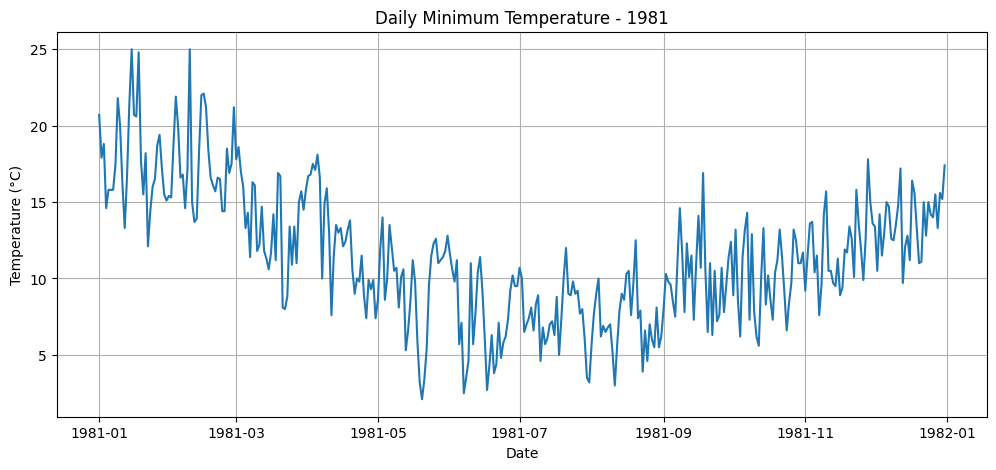

In [47]:
year_data = df[df['Date'].dt.year == 1981]

plt.figure(figsize=(12, 5))
plt.plot(year_data['Date'], year_data['Temp'])
plt.title("Daily Minimum Temperature - 1981")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid()
plt.show()

In [48]:
temperatures = df['Temp'].values

split_index = int(len(temperatures) * 0.8)
train_data = temperatures[:split_index]
test_data = temperatures[split_index:]

print("Training Data:", len(train_data))
print("Testing Data:", len(test_data))

Training Data: 2920
Testing Data: 730


In [49]:
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_data.reshape(-1, 1))
test_scaled = scaler.transform(test_data.reshape(-1, 1))

In [50]:
look_back = 30

X_train = []
y_train = []

for i in range(look_back, len(train_scaled)):
    X_train.append(train_scaled[i-look_back:i])
    y_train.append(train_scaled[i])

X_train = np.array(X_train)
y_train = np.array(y_train)

test_combined = np.concatenate((train_scaled[-look_back:], test_scaled))

X_test = []
y_test = []

for i in range(look_back, len(test_combined)):
    X_test.append(test_combined[i-look_back:i])
    y_test.append(test_combined[i])

X_test = np.array(X_test)
y_test = np.array(y_test)

print("X_train Shape:", X_train.shape)
print("y_train Shape:", y_train.shape)
print("X_test Shape:", X_test.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (2890, 30, 1)
y_train Shape: (2890, 1)
X_test Shape: (730, 30, 1)
y_test Shape: (730, 1)


In [51]:
model = keras.Sequential([layers.Input(shape=(30, 1)),layers.GRU(32, activation='tanh'),layers.Dense(1)])
model.compile(optimizer='adam',loss='mse')

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 32)             │         3,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

In [52]:
baseline_pred = scaler.inverse_transform(
    X_test[:, -1, :])
actual_temp = scaler.inverse_transform(y_test)
baseline_rmse = np.sqrt(
    mean_squared_error(actual_temp, baseline_pred)
)

print("Naive Baseline RMSE:", baseline_rmse, "°C")

Naive Baseline RMSE: 2.4809051596058453 °C


4.3 Train & Evaluate

Epoch 1/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 0.0444 - val_loss: 0.0123
Epoch 2/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.0128 - val_loss: 0.0107
Epoch 3/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0110 - val_loss: 0.0100
Epoch 4/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0101 - val_loss: 0.0097
Epoch 5/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.0098 - val_loss: 0.0097
Epoch 6/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0095 - val_loss: 0.0094
Epoch 7/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0093 - val_loss: 0.0093
Epoch 8/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0093 - val_loss: 0.0094
Epoch 9/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0093 - val_loss: 0.0092
Epoch 10/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0091 - val_loss: 0.0092
Epoch 11/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0090 - val_loss: 0.0094
Epoch 12/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0

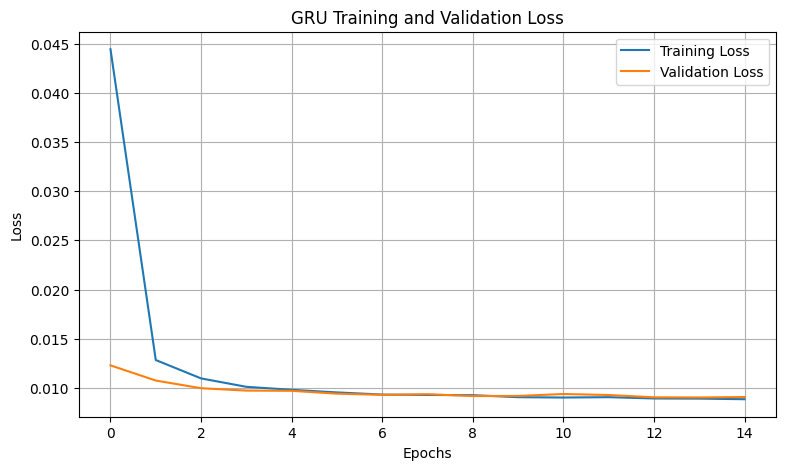

In [53]:
history = model.fit(X_train,y_train,epochs=15,batch_size=32,validation_split=0.1,verbose=1)

plt.figure(figsize=(9, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("GRU Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

In [54]:
y_pred_scaled = model.predict(X_test)
y_pred = scaler.inverse_transform(y_pred_scaled)
y_actual = scaler.inverse_transform(y_test)

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


In [55]:
gru_rmse = np.sqrt(mean_squared_error(y_actual, y_pred))

gru_mae = mean_absolute_error(y_actual, y_pred)

print("GRU RMSE:", gru_rmse, "°C")
print("GRU MAE:", gru_mae, "°C")

GRU RMSE: 2.225738008414437 °C
GRU MAE: 1.7483977951415597 °C


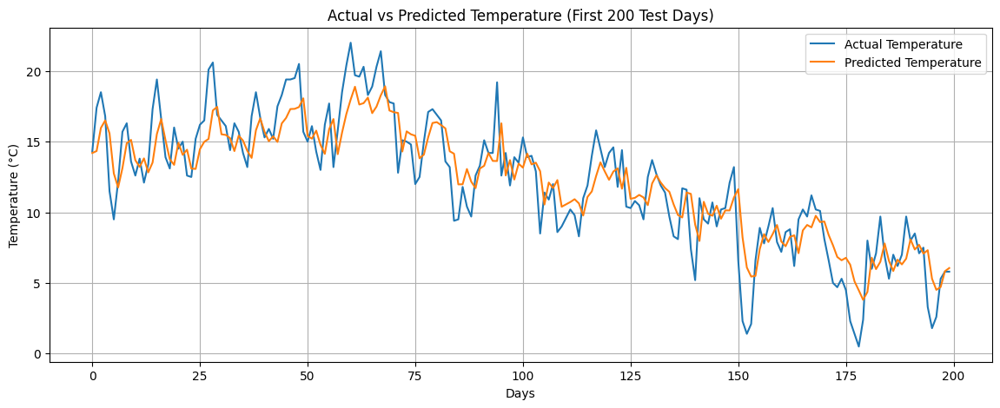

In [56]:
plt.figure(figsize=(14, 5))

plt.plot(y_actual[:200], label='Actual Temperature')
plt.plot(y_pred[:200], label='Predicted Temperature')

plt.title("Actual vs Predicted Temperature (First 200 Test Days)")
plt.xlabel("Days")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid()
plt.show()

4.4 Save & Reflect

In [57]:
model.save('rnn_temperature_model.h5')
print("Model Saved Successfully!")

Model Saved Successfully!


1. How does a GRU differ from a SimpleRNN? What are its gates?

GRU (Gated Recurrent Unit) is a type of RNN that uses gates to control information flow and remember important information.

It has two gates:
- Update Gate: Decides how much previous information should be retained.
- Reset Gate: Decides how much previous information should be forgotten.
GRU helps solve the vanishing gradient problem and captures long-term dependencies better than a SimpleRNN.

2. Why did we fit the scaler on the training data only?

We fit the scaler only on training data to prevent data leakage. The testing data must remain unseen during training so that model evaluation is fair.

3. Did your GRU beat the naive baseline?

Compare the RMSE values of both models.
- If GRU RMSE is lower, GRU performs better.
- If baseline RMSE is lower, the naive baseline performs better.
4. What do RMSE and MAE mean in °C?
- RMSE (Root Mean Squared Error): Measures the average prediction error while giving more importance to larger errors.
- MAE (Mean Absolute Error): Measures the average absolute difference between actual and predicted temperatures.

##Step 5: Transformers — Fill-Mask, Question Answering & Text Generation
5.1  Setup & Fill-Mask

In [58]:
from transformers import pipeline, set_seed

In [59]:
unmasker = pipeline('fill-mask',model='distilbert-base-uncased')

masked_sentences = [
    "The capital of India is [MASK].",
    "The Taj Mahal is located in [MASK].",
    "ISRO is India's space research [MASK].",
    "UPI is used for digital [MASK].",
    "Mumbai is located in the Indian state of [MASK]."
]

for sentence in masked_sentences:
    print("\nSentence:", sentence)
    predictions = unmasker(sentence, top_k=3)

    for prediction in predictions:
        print("Token:",prediction['token_str'],"| Score:",prediction['score'])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
Device set to use cpu



Sentence: The capital of India is [MASK].
Token: pune | Score: 0.15586887300014496
Token: bangalore | Score: 0.14746436476707458
Token: mumbai | Score: 0.07776282727718353

Sentence: The Taj Mahal is located in [MASK].
Token: agra | Score: 0.1567147821187973
Token: delhi | Score: 0.1275685876607895
Token: lahore | Score: 0.10892866551876068

Sentence: ISRO is India's space research [MASK].
Token: agency | Score: 0.2866209149360657
Token: organisation | Score: 0.2239968180656433
Token: institute | Score: 0.09559029340744019

Sentence: UPI is used for digital [MASK].
Token: imaging | Score: 0.07607582211494446
Token: cameras | Score: 0.05278430134057999
Token: photography | Score: 0.04661913588643074

Sentence: Mumbai is located in the Indian state of [MASK].
Token: maharashtra | Score: 0.9803850650787354
Token: gujarat | Score: 0.00942721776664257
Token: goa | Score: 0.0030451915226876736


For the sentence “The capital of India is [MASK].”, the model should predict Delhi among its likely answers.

What the model does:
The fill-mask model predicts the most likely missing word based on the surrounding context.

5.2 Question Answering

In [60]:
# !pip uninstall transformers -y
# !pip install "transformers<5"

In [61]:
paragraphs = [
    """ISRO is the Indian Space Research Organisation. It is responsible for India's space programme and conducts satellite and space missions. ISRO has achieved important milestones in space exploration.""",
    """The Taj Mahal is a famous monument located in Agra, India. It was built by Mughal Emperor Shah Jahan. It is known for its beautiful white marble architecture.""",
    """Indian Railways is one of the largest railway networks in the world. It connects many cities and towns across India. Millions of passengers use railway services every day.""",
    """UPI stands for Unified Payments Interface. It allows users to transfer money digitally between bank accounts. UPI has made digital payments easier and faster in India.""",
    """Mumbai is one of India's major cities and is located in Maharashtra. It is an important financial and commercial centre. Mumbai is also known for the Indian film industry."""
]

qa = pipeline('question-answering', model='distilbert-base-cased-distilled-squad')

model.safetensors:   0%|          | 0.00/261M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cpu


In [62]:
questions = [
    "What does ISRO stand for?",
    "Who is the current chairman of ISRO?",

    "Where is the Taj Mahal located?",
    "Who built the Taj Mahal?",

    "What does Indian Railways connect?",
    "How many railway stations are there in India?",

    "What does UPI stand for?",
    "What does UPI allow users to do?",

    "Which state is Mumbai located in?",
    "Which city is the capital of India?"]

In [63]:
contexts = [paragraphs[0],paragraphs[0],paragraphs[1],paragraphs[1],paragraphs[2],paragraphs[2],paragraphs[3],paragraphs[3],paragraphs[4],paragraphs[4]]

In [64]:
results_list = []

for question, context in zip(questions, contexts):

    result = qa(question=question,context=context)
    results_list.append({
        'Question': question,
        'Predicted_Answer': result['answer'],
        'Confidence_Score': result['score']
    })

qa_results = pd.DataFrame(results_list)
print(qa_results)

                                        Question  \
0                      What does ISRO stand for?   
1           Who is the current chairman of ISRO?   
2                Where is the Taj Mahal located?   
3                       Who built the Taj Mahal?   
4             What does Indian Railways connect?   
5  How many railway stations are there in India?   
6                       What does UPI stand for?   
7               What does UPI allow users to do?   
8              Which state is Mumbai located in?   
9            Which city is the capital of India?   

                                 Predicted_Answer  Confidence_Score  
0              Indian Space Research Organisation          0.941140  
1              Indian Space Research Organisation          0.443401  
2                                     Agra, India          0.824555  
3                       Mughal Emperor Shah Jahan          0.943274  
4                           many cities and towns          0.514259  
5      

In [65]:
qa_results['Correct'] = [
    'Yes',
    'No',
    'Yes',
    'Yes',
    'Yes',
    'No',
    'Yes',
    'Yes',
    'Yes',
    'No'
]

print(qa_results)

                                        Question  \
0                      What does ISRO stand for?   
1           Who is the current chairman of ISRO?   
2                Where is the Taj Mahal located?   
3                       Who built the Taj Mahal?   
4             What does Indian Railways connect?   
5  How many railway stations are there in India?   
6                       What does UPI stand for?   
7               What does UPI allow users to do?   
8              Which state is Mumbai located in?   
9            Which city is the capital of India?   

                                 Predicted_Answer  Confidence_Score Correct  
0              Indian Space Research Organisation          0.941140     Yes  
1              Indian Space Research Organisation          0.443401      No  
2                                     Agra, India          0.824555     Yes  
3                       Mughal Emperor Shah Jahan          0.943274     Yes  
4                           many citi

In [66]:
correct_count = (qa_results['Correct'] == 'Yes').sum()
print("Correct Answers:", correct_count, "out of 10")

Correct Answers: 7 out of 10


5.3 Text Generation

In [67]:
gen = pipeline('text-generation',model='distilgpt2')
set_seed(42)

prompts = [
    "India is a country where",
    "Deep learning is",
    "Artificial intelligence can"
]

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/353M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cpu


In [68]:
for prompt in prompts:

    print("\nPrompt:", prompt)
    outputs = gen(prompt,max_new_tokens=30,do_sample=True,num_return_sequences=2)

    for i, output in enumerate(outputs):
        print("\nContinuation", i + 1)
        print(output['generated_text'])

Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.



Prompt: India is a country where


Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.



Continuation 1
India is a country where more than 3 percent of people are working and we have a great opportunity to help improve our lives and our health.





And

Continuation 2
India is a country where there was no threat to Israel from a missile strike. The recent Israeli missile strike in Gaza made it seem that the US and Israeli authorities were being prepared

Prompt: Deep learning is


Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.



Continuation 1
Deep learning is a new feature of the web. All we have to do is learn what's going on in Web programming.




The Web is

Continuation 2
Deep learning is a huge thing. It’s amazing.”

Prompt: Artificial intelligence can

Continuation 1
Artificial intelligence can make all of our lives the same.























Continuation 2
Artificial intelligence can help us understand the world better.


In [69]:
prompt = "India is a country where"

output_low = gen(prompt,max_new_tokens=30,do_sample=True,temperature=0.5,num_return_sequences=1)
output_high = gen(prompt,max_new_tokens=30,do_sample=True,temperature=1.5,num_return_sequences=1)

print("Temperature = 0.5")
print(output_low[0]['generated_text'])
print("\nTemperature = 1.5")
print(output_high[0]['generated_text'])

Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


Temperature = 0.5
India is a country where the country is the most powerful state in the world.




















Temperature = 1.5
India is a country where we want change rather than the pursuit of perfection," she noted by phone here and via Facebook, before she launched a campaign of protesting the actions of anti


5.4 Visualise & Reflect

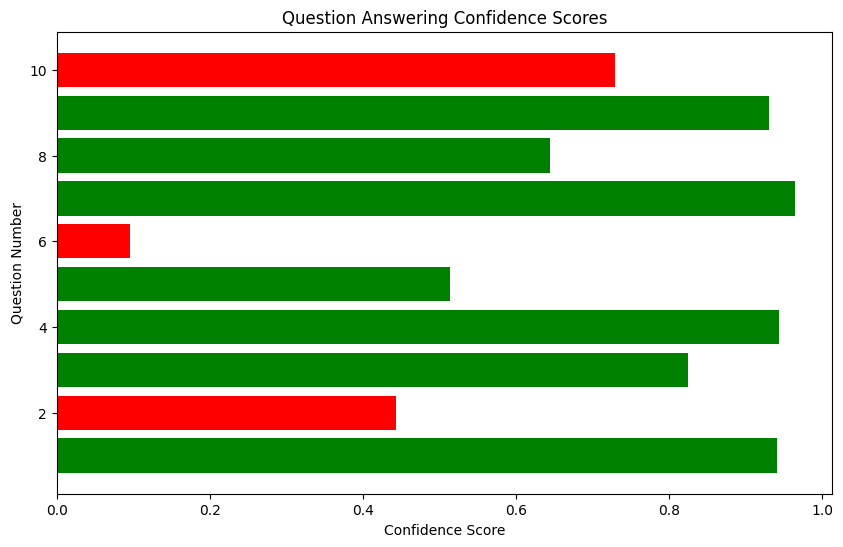

In [70]:
plot_results = qa_results.copy()
plot_results['Question_Number'] = range(1, 11)

colors = [
    'green' if value == 'Yes' else 'red'
    for value in plot_results['Correct']
]

plt.figure(figsize=(10, 6))
plt.barh(plot_results['Question_Number'],plot_results['Confidence_Score'],color=colors)
plt.xlabel("Confidence Score")
plt.ylabel("Question Number")
plt.title("Question Answering Confidence Scores")

plt.show()

1. What is the difference between an encoder model and a decoder model?  
An encoder model, such as BERT, processes the complete input and learns the relationship between words. It is useful for understanding tasks such as fill-mask and question answering.  
A decoder model, such as GPT-2, generates text one word at a time based on previously generated words. It is mainly used for text generation.

2. What is self-attention?  
Self-attention allows a Transformer to identify which words in a sentence are important and understand relationships between different words.

3. What does “extractive” QA mean?
Extractive Question Answering means the model selects or extracts the answer directly from the given paragraph instead of generating a completely new answer.

4. What does temperature control?  
Temperature controls the randomness of generated text.
- Lower temperature → more predictable output.
- Higher temperature → more random and creative output.

5. Why can generated text sound fluent but be factually wrong?  
A text generation model predicts likely next words based on patterns learned during training. It does not always verify whether the generated information is factually correct.

In [76]:
results = pd.DataFrame({
    'Step / Topic': [
        'ANN',
        'OpenCV',
        'CNN',
        'RNN',
        'Transformer'
    ],

    'Task Type': [
        'Multi-class Classification',
        'Image Processing & Face Detection',
        'Image Classification',
        'Time-series Regression',
        'NLP / Transformer Inference'
    ],

    'Dataset Used': [
        'Wine Dataset (178 samples)',
        '5 Images',
        'MNIST (20,000 train, 4,000 test)',
        'Melbourne Temperature (3,650 records)',
        '5 Paragraphs, 10 Questions'
    ],

    'Key Metric': [
        'Accuracy',
        'Number of Faces Detected',
        'Accuracy',
        'RMSE (°C)',
        'Correct Answers'
    ],

    'Result Achieved': [
        '95.64 (%)',
        '1',
        '97.62 (%)',
        '2.225 (°C)',
        '7'
    ]
})

display(results)

,Step / Topic,Task Type,Dataset Used,Key Metric,Result Achieved
0,ANN,Multi-class Classification,Wine Dataset (178 samples),Accuracy,95.64 (%)
1,OpenCV,Image Processing & Face Detection,5 Images,Number of Faces Detected,1
2,CNN,Image Classification,"MNIST (20,000 train, 4,000 test)",Accuracy,97.62 (%)
3,RNN,Time-series Regression,"Melbourne Temperature (3,650 records)",RMSE (°C),2.225 (°C)
4,Transformer,NLP / Transformer Inference,"5 Paragraphs, 10 Questions",Correct Answers,7


## 6.2 Written Reflection

- **Most challenging step:** Step 5 (Transformers) was the most challenging because it involved using different pre-trained models for fill-mask, question answering and text generation. I also faced a compatibility issue with the Transformers library and had to resolve it.

- **Best result relative to effort:** Step 3 (CNN) gave a good result compared with the effort required. The CNN was able to recognize handwritten digits effectively using convolution and pooling layers.

- **ANN architecture improvement:** If I had more time, I would experiment with additional hidden layers, different numbers of neurons, dropout and batch normalization to improve accuracy and reduce overfitting.

- **Why CNN needs fewer parameters than ANN:** CNN uses shared filters and local connections to extract image features. ANN uses fully connected layers, which require more weights. Therefore, CNN can process images efficiently with fewer parameters.

- **GRU vs Transformer:** GRU processes sequential data step by step using update and reset gates to control information flow. Transformer uses self-attention to understand relationships between different words or elements in a sequence and can process them in parallel.

- **Why GPT-style models can produce incorrect facts:** GPT-style models predict the next token based on learned patterns. They do not always verify factual information. To reduce incorrect information, I would use reliable data sources, fact-checking, retrieval-augmented generation (RAG) and human verification.

- **Where Haar Cascade is useful:** Haar Cascade is useful for simple face detection applications where low computational resources and fast processing are important. It does not require model training, unlike many deep learning approaches. However, CNN-based face detection generally performs better in complex conditions such as poor lighting, different angles and occlusions.